# 📊 01. Smart Grid Dataset Analysis & Exploratory Data Analysis (EDA)

### **Research Focus: Non-Technical Losses (NTL) in Smart Distribution Grids**
Non-Technical Losses (NTL), predominantly caused by **electricity theft**, cost electrical utilities over **$96 billion annually worldwide**. Beyond revenue loss, energy theft causes local distribution transformer overloads, voltage instability, and compromised dispatch models.

This notebook performs comprehensive exploratory data analysis across:
1. **Real-World Benchmark: State Grid Corporation of China (SGCC) Smart Meter Dataset** (42,372 meters, 1,035 daily time steps).
2. **High-Frequency Smart Meter Telemetry Simulator** (Hourly readings across industrial, commercial, residential, and rural feeders).
3. **Theft Attack Taxonomy**: Mathematical and graphical characterization of bypass, scaling, flatlining, and intermittent theft vectors.

In [2]:
import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Dynamically locate project root
workspace_root = Path.cwd()
if workspace_root.name == "notebooks" or not (workspace_root / "fl_system").exists():
    workspace_root = workspace_root.parent
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

print(f"✓ Project Root: {workspace_root}")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['figure.dpi'] = 120

✓ Project Root: d:\users\Group Project\Blockchain-Based Byzantine-Resilient Federated Learning for Smart Grid Energy Theft Detection


## 1. Real-World Benchmark: State Grid Corporation of China (SGCC) Dataset

The SGCC dataset provides daily energy consumption telemetry from tens of thousands of Chinese electricity consumers over 1,035 consecutive days (January 2014 to October 2016).
- **`CONS_NO`**: Pseudonymized consumer/meter identification hash.
- **`FLAG`**: Ground-truth utility audit label: `0 = Honest / Normal Consumer`, `1 = Energy Thief / Anomaly`.
- Date columns (`YYYY/M/D`): Daily consumption in kilowatt-hours (kWh).

In [7]:
sgcc_raw_path = workspace_root / "data" / "raw" / "data.csv"

print(f"Inspecting SGCC dataset at: {sgcc_raw_path}")
print(f"File size: {sgcc_raw_path.stat().st_size / (1024 * 1024):.2f} MB")

# Load sample of SGCC for fast interactive exploration
sgcc_sample = pd.read_csv(sgcc_raw_path, nrows=42372)
print(f"Sample dimensions: {sgcc_sample.shape[0]} meters, {sgcc_sample.shape[1]} columns (FLAG + 1034 daily steps)")
sgcc_sample.head(9).iloc[:, :8]

Inspecting SGCC dataset at: d:\users\Group Project\Blockchain-Based Byzantine-Resilient Federated Learning for Smart Grid Energy Theft Detection\data\raw\data.csv
File size: 167.08 MB
Sample dimensions: 42372 meters, 1036 columns (FLAG + 1034 daily steps)


,CONS_NO,FLAG,2014/1/1,2014/1/10,2014/1/11,2014/1/12,2014/1/13,2014/1/14
0,0387DD8A07E07FDA6271170F86AD9151,1,NaN,NaN,NaN,NaN,NaN,NaN
1,01D6177B5D4FFE0CABA9EF17DAFC2B84,1,NaN,NaN,NaN,NaN,NaN,NaN
2,4B75AC4F2D8434CFF62DB64D0BB43103,1,NaN,NaN,NaN,NaN,NaN,NaN
3,B32AC8CC6D5D805AC053557AB05F5343,1,NaN,NaN,NaN,NaN,NaN,NaN
4,EDFC78B07BA2908B3395C4EB2304665E,1,2.90,3.42,3.81,4.58,3.56,4.25
5,6BCFD78138BC72A9BA1BFB0B79382192,1,NaN,NaN,NaN,NaN,NaN,NaN
6,34C1954AA3703C4F8BD8EAEA7C4B7B83,1,0.11,0.53,0.45,0.51,1.32,0.71
7,768309B0EB11FD436CEE5ABFB84F4C0C,1,0.91,0.86,1.10,0.66,5.82,3.17
8,D0A186208CE83FBCCF730857C9A75B6F,1,NaN,NaN,NaN,NaN,NaN,NaN


### 1.1 Class Imbalance Analysis (Theft vs. Honest)

In real-world distribution systems, energy theft represents a severe minority class. Typically, only 5% to 10% of customers engage in unauthorized consumption or meter tampering.
Detecting this requires specialized handling (e.g. weighted cross-entropy loss, PR-AUC evaluation) rather than naive accuracy.

--- Class Distribution in SGCC Benchmark ---
Normal Consumers (FLAG=0): 38757 (91.47%)
Energy Thieves   (FLAG=1): 3615 (8.53%)
Class Imbalance Ratio (Neg/Pos): 10.7 : 1


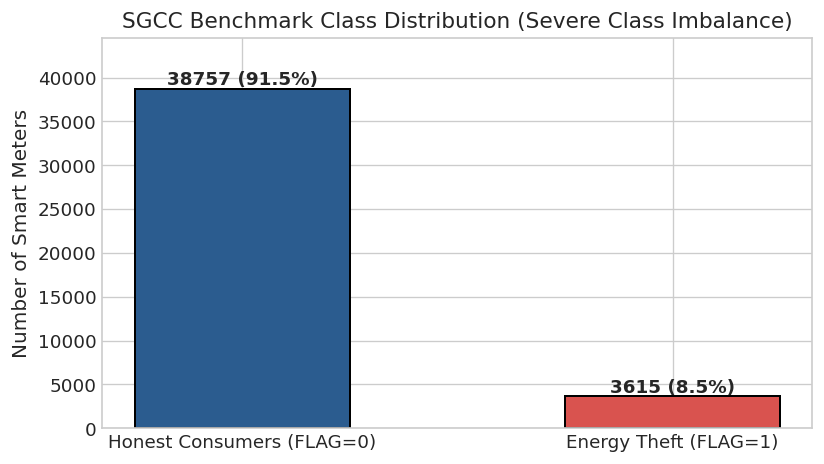

In [8]:
flag_counts = sgcc_sample['FLAG'].value_counts()
flag_pcts = sgcc_sample['FLAG'].value_counts(normalize=True) * 100

print("--- Class Distribution in SGCC Benchmark ---")
print(f"Normal Consumers (FLAG=0): {flag_counts.get(0, 0)} ({flag_pcts.get(0, 0):.2f}%)")
print(f"Energy Thieves   (FLAG=1): {flag_counts.get(1, 0)} ({flag_pcts.get(1, 0):.2f}%)")
print(f"Class Imbalance Ratio (Neg/Pos): {flag_counts.get(0, 0) / max(1, flag_counts.get(1, 0)):.1f} : 1")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Honest Consumers (FLAG=0)', 'Energy Theft (FLAG=1)'], 
              [flag_counts.get(0, 0), flag_counts.get(1, 0)],
              color=['#2b5c8f', '#d9534f'], width=0.5, edgecolor='black', linewidth=1.2)
ax.set_ylabel('Number of Smart Meters')
ax.set_title('SGCC Benchmark Class Distribution (Severe Class Imbalance)')

for bar, pct in zip(bars, [flag_pcts.get(0, 0), flag_pcts.get(1, 0)]):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f'{yval} ({pct:.1f}%)', 
            ha='center', va='bottom', fontweight='bold')
ax.set_ylim(0, max(flag_counts) * 1.15)
plt.tight_layout()
plt.show()



### 1.2 Missing Value Distribution in Real-World Grid Telemetry

Smart meter communication channels frequently suffer from packet drops, gateway timeouts, and power outages. Here we analyze missing values across time.

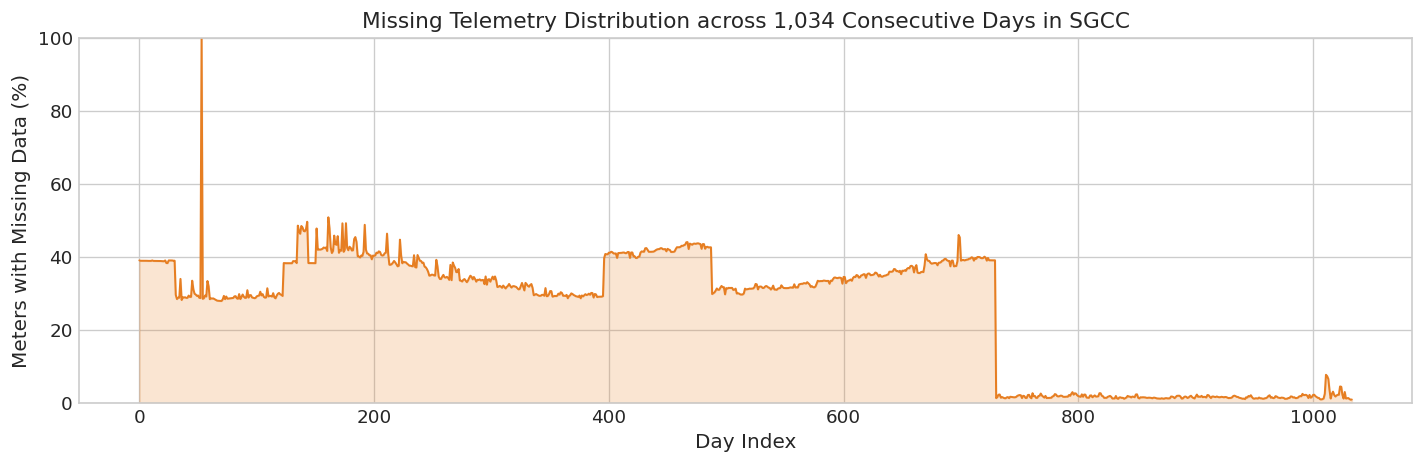

Average missing rate across all days: 25.64%
Maximum single-day missing rate: 99.96%


In [9]:
date_cols = [c for c in sgcc_sample.columns if c not in ['CONS_NO', 'FLAG']]
missing_per_day = sgcc_sample[date_cols].isnull().mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(len(missing_per_day)), missing_per_day.values, color='#e67e22', lw=1.2)
ax.fill_between(range(len(missing_per_day)), 0, missing_per_day.values, color='#e67e22', alpha=0.2)
ax.set_title('Missing Telemetry Distribution across 1,034 Consecutive Days in SGCC')
ax.set_xlabel('Day Index')
ax.set_ylabel('Meters with Missing Data (%)')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()

print(f"Average missing rate across all days: {missing_per_day.mean():.2f}%")
print(f"Maximum single-day missing rate: {missing_per_day.max():.2f}%")

### 1.3 Time-Series Trajectory: Honest Consumers vs. Energy Thieves

Let's extract consumption trajectories for 3 honest consumers and 3 confirmed energy thieves over a 180-day window to observe theft signatures.

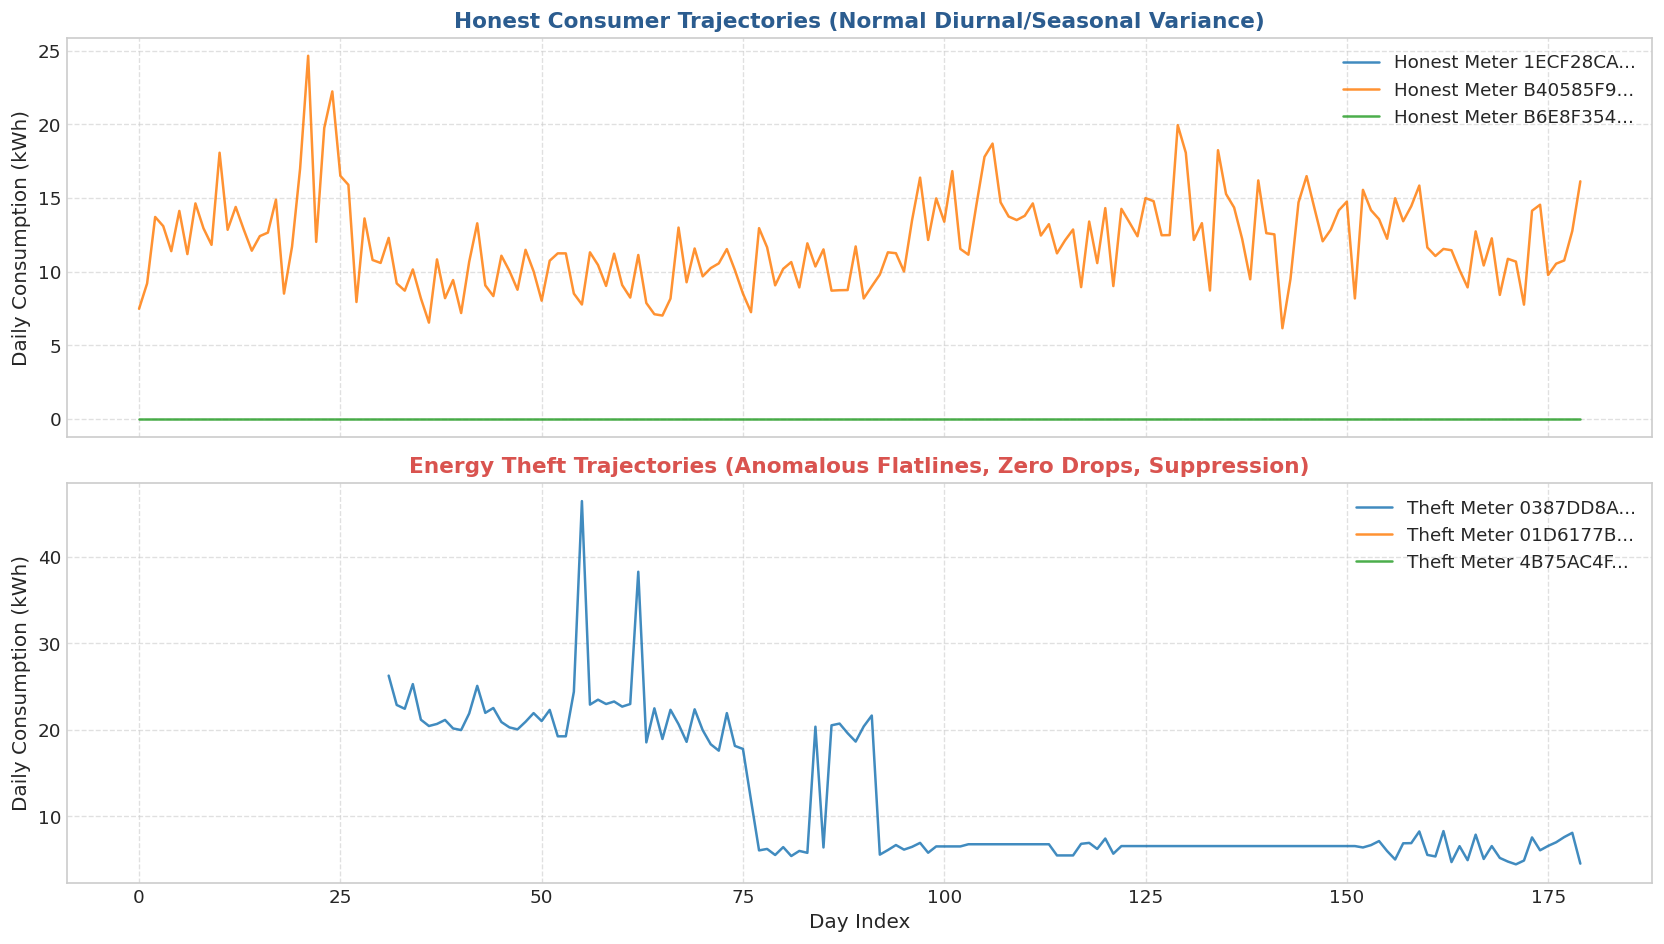

In [10]:
honest_indices = sgcc_sample[sgcc_sample['FLAG'] == 0].index[:3]
thief_indices = sgcc_sample[sgcc_sample['FLAG'] == 1].index[:3]

window_days = date_cols[:180]

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Plot Honest Consumers
for idx in honest_indices:
    cons = sgcc_sample.loc[idx, window_days].ffill().values
    axes[0].plot(range(180), cons, label=f"Honest Meter {sgcc_sample.loc[idx, 'CONS_NO'][:8]}...", alpha=0.85, lw=1.5)
axes[0].set_title('Honest Consumer Trajectories (Normal Diurnal/Seasonal Variance)', fontweight='bold', color='#2b5c8f')
axes[0].set_ylabel('Daily Consumption (kWh)')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Energy Thieves
for idx in thief_indices:
    cons = sgcc_sample.loc[idx, window_days].ffill().values
    axes[1].plot(range(180), cons, label=f"Theft Meter {sgcc_sample.loc[idx, 'CONS_NO'][:8]}...", alpha=0.85, lw=1.5)
axes[1].set_title('Energy Theft Trajectories (Anomalous Flatlines, Zero Drops, Suppression)', fontweight='bold', color='#d9534f')
axes[1].set_xlabel('Day Index')
axes[1].set_ylabel('Daily Consumption (kWh)')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 2. High-Frequency Smart Meter Telemetry Simulator

In modern Advanced Metering Infrastructure (AMI), smart meters report consumption at 15-minute or 1-hour intervals.
Our simulator creates realistic non-IID consumer partitions corresponding to 5 distribution substations:
- **`client_A` (Industrial Substation)**: High base load (20–60 kWh/h), multi-shift manufacturing, inductive motor surges.
- **`client_B` (Commercial Center)**: Sharp business-hour peak (8 AM – 7 PM), near-zero night baseline.
- **`client_C` (Urban High-Density Residential)**: Moderate dual peaks (morning 7–9 AM, evening 6–10 PM).
- **`client_D` (Suburban Residential)**: Prominent evening cooking and EV charging spikes.
- **`client_E` (Rural Mixed / Agricultural)**: Seasonal pumping, solar PV back-feeding, intermittent heavy loads.

In [11]:
sim_path = workspace_root / "data" / "synthetic" / "simulated_meter_data.csv"

if sim_path.exists():
    df_sim = pd.read_csv(sim_path, nrows=5000)
    print(f"Loaded {len(df_sim)} hourly readings from Smart Meter Simulator")
    print(f"Columns: {list(df_sim.columns)}")
    print(df_sim[['timestamp', 'meter_id', 'client_id', 'consumption_kwh', 'simulated_theft_label']].head(9))
else:
    print("Synthetic file not found at expected path. Checking processed benchmark...")

Loaded 5000 hourly readings from Smart Meter Simulator
Columns: ['timestamp', 'meter_id', 'client_id', 'consumption_kwh', 'meter_status', 'event_type', 'hardware_tamper_flag', 'simulated_theft_label', 'simulated_theft_type', 'simulated_actual_kwh', 'simulated_unreported_kwh']
             timestamp    meter_id client_id  consumption_kwh  \
0  2026-01-01 00:00:00  MTR-A-0001  client_A           0.3837   
1  2026-01-01 00:00:00  MTR-A-0002  client_A         119.6805   
2  2026-01-01 00:00:00  MTR-A-0003  client_A          62.3120   
3  2026-01-01 00:00:00  MTR-A-0004  client_A         148.5133   
4  2026-01-01 00:00:00  MTR-A-0005  client_A           0.3043   
5  2026-01-01 00:00:00  MTR-A-0006  client_A         140.1697   
6  2026-01-01 00:00:00  MTR-A-0007  client_A           0.4744   
7  2026-01-01 00:00:00  MTR-A-0008  client_A              NaN   
8  2026-01-01 00:00:00  MTR-A-0009  client_A           7.0837   

   simulated_theft_label  
0                      0  
1                 

### 2.1 Substation Non-IID Diversity (Clients A to E)

Federated learning in smart grids must handle severe non-IID (heterogeneous) data distributions across substations without mistaking domain diversity for Byzantine attacks.

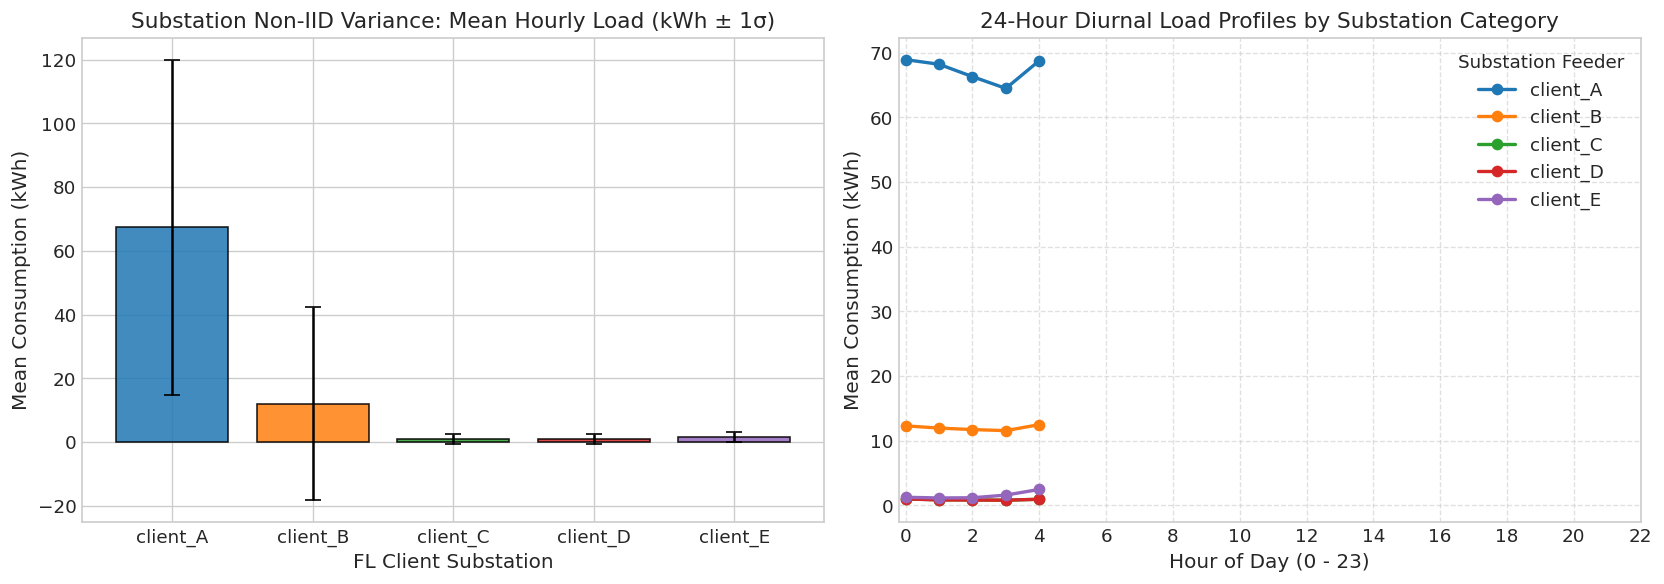

In [12]:
if sim_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Mean consumption per substation
    client_stats = df_sim.groupby('client_id')['consumption_kwh'].agg(['mean', 'std', 'count']).reset_index()
    palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    axes[0].bar(client_stats['client_id'], client_stats['mean'], yerr=client_stats['std'], 
                capsize=5, color=palette, edgecolor='black', alpha=0.85)
    axes[0].set_title('Substation Non-IID Variance: Mean Hourly Load (kWh ± 1σ)')
    axes[0].set_ylabel('Mean Consumption (kWh)')
    axes[0].set_xlabel('FL Client Substation')
    
    # Diurnal hourly profile per substation
    df_sim['hour'] = pd.to_datetime(df_sim['timestamp']).dt.hour
    hourly_profiles = df_sim.groupby(['client_id', 'hour'])['consumption_kwh'].mean().unstack(level=0)
    
    for c_id, col in zip(hourly_profiles.columns, palette):
        axes[1].plot(hourly_profiles.index, hourly_profiles[c_id], marker='o', label=c_id, color=col, lw=2)
    
    axes[1].set_title('24-Hour Diurnal Load Profiles by Substation Category')
    axes[1].set_xlabel('Hour of Day (0 - 23)')
    axes[1].set_ylabel('Mean Consumption (kWh)')
    axes[1].set_xticks(range(0, 24, 2))
    axes[1].legend(title="Substation Feeder")
    axes[1].grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()

## 3. Mathematical Taxonomy of Energy Theft Attack Vectors

In energy distribution networks, dishonest consumers utilize multiple physical and cyber tampering methods:

1. **Constant Bypass (Mean Reduction)**:
   $$c'_t = \max(0, c_t - eta), \quad eta > 0$$
2. **Percentage Scaling (Linear Resistance Tap)**:
   $$c'_t = lpha \cdot c_t, \quad 0 < lpha < 1$$
3. **Peak Shaving (Threshold Bypass)**:
   $$c'_t = egin{cases} c_t & 	ext{if } c_t \le c_{	ext{thresh}} \\ c_{	ext{thresh}} & 	ext{if } c_t > c_{	ext{thresh}} \end{cases}$$
4. **Random Walk / Dynamic Multiplier**:
   $$c'_t = lpha_t \cdot c_t, \quad lpha_t \sim \mathcal{U}(0.2, 0.7)$$

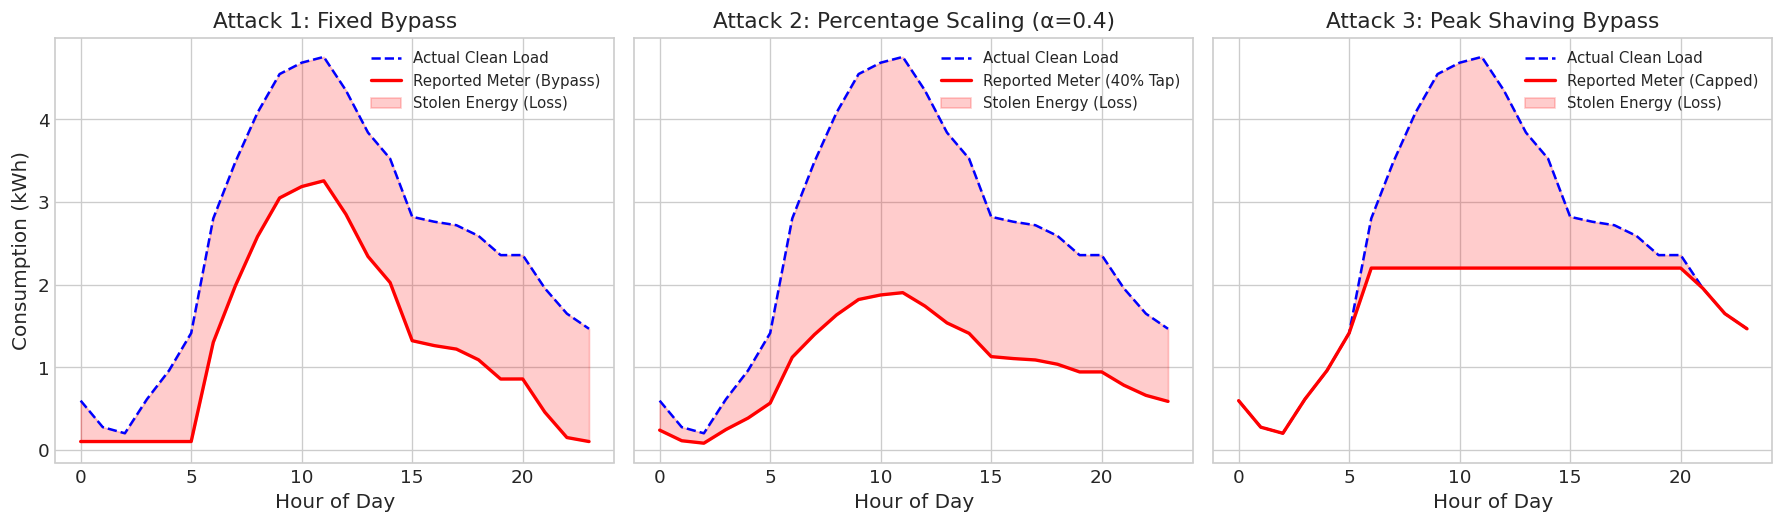

In [13]:
# Demonstration of mathematical theft transformations on a clean 24-hour load curve
t = np.arange(24)
clean_load = 2.5 + 1.8 * np.sin(2 * np.pi * (t - 6) / 24) + 0.8 * np.sin(2 * np.pi * (t - 18) / 12) + np.random.normal(0, 0.15, 24)
clean_load = np.maximum(0.2, clean_load)

# 1. Bypass (Fixed Drop)
bypass_theft = np.maximum(0.1, clean_load - 1.5)

# 2. Percentage scaling (alpha = 0.40)
scaled_theft = clean_load * 0.40

# 3. Peak shaving (c_thresh = 2.2)
peak_shaved = np.minimum(clean_load, 2.2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

# Bypass plot
axes[0].plot(t, clean_load, 'b--', label='Actual Clean Load', lw=1.5)
axes[0].plot(t, bypass_theft, 'r-', label='Reported Meter (Bypass)', lw=2)
axes[0].fill_between(t, bypass_theft, clean_load, color='red', alpha=0.2, label='Stolen Energy (Loss)')
axes[0].set_title('Attack 1: Fixed Bypass')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Consumption (kWh)')
axes[0].legend(loc='upper right', fontsize=9)

# Scaling plot
axes[1].plot(t, clean_load, 'b--', label='Actual Clean Load', lw=1.5)
axes[1].plot(t, scaled_theft, 'r-', label='Reported Meter (40% Tap)', lw=2)
axes[1].fill_between(t, scaled_theft, clean_load, color='red', alpha=0.2, label='Stolen Energy (Loss)')
axes[1].set_title('Attack 2: Percentage Scaling (α=0.4)')
axes[1].set_xlabel('Hour of Day')
axes[1].legend(loc='upper right', fontsize=9)

# Peak shaving plot
axes[2].plot(t, clean_load, 'b--', label='Actual Clean Load', lw=1.5)
axes[2].plot(t, peak_shaved, 'r-', label='Reported Meter (Capped)', lw=2)
axes[2].fill_between(t, peak_shaved, clean_load, color='red', alpha=0.2, label='Stolen Energy (Loss)')
axes[2].set_title('Attack 3: Peak Shaving Bypass')
axes[2].set_xlabel('Hour of Day')
axes[2].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

## 4. Key Findings & Design Takeaways for Federated Learning

| Characteristic | Smart Grid Reality | Federated Learning Implication |
| :--- | :--- | :--- |
| **Severe Class Imbalance** | ~8–10% positive theft instances | Loss function requires class weighting (`pos_weight`); evaluation requires PR-AUC and F1. |
| **Regional Non-IID Diversity** | Industrial (Client A) vs. Rural (Client E) have 100x different baselines | Simple Euclidean gradient outlier detection will falsely flag honest industrial or rural clients. |
| **Transient Edge Features** | Bypasses cause sharp step-changes in consumption | 1D temporal convolutions (CNN) are essential to capture rapid step-downs, while LSTM captures seasonal cycles. |
| **Data Privacy (GDPR/AMI)** | High-frequency telemetry reveals home occupancy & lifestyle | Federated Learning keeps raw sequences strictly at the substation; only parameter updates are communicated. |